In [2]:
from google.colab import files
uploaded = files.upload()

Saving T1.csv to T1.csv


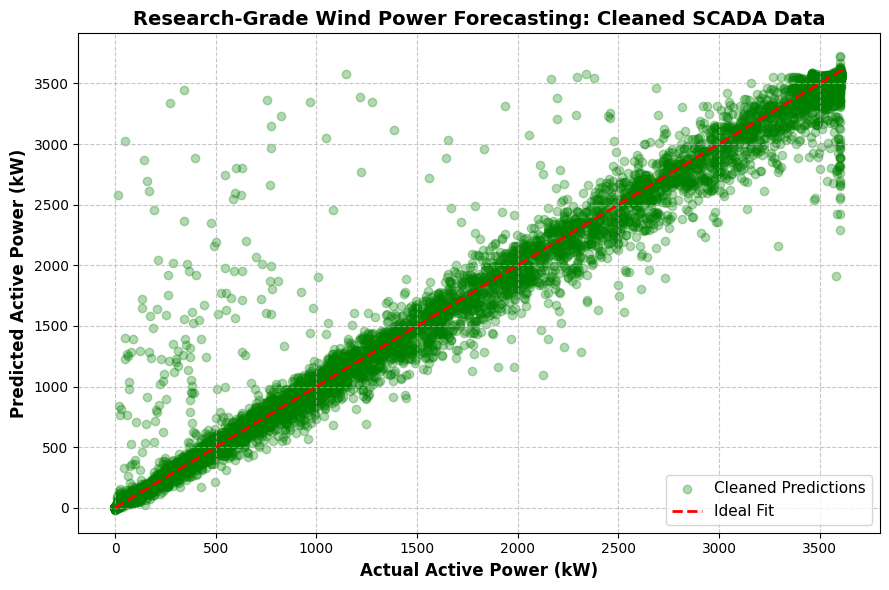

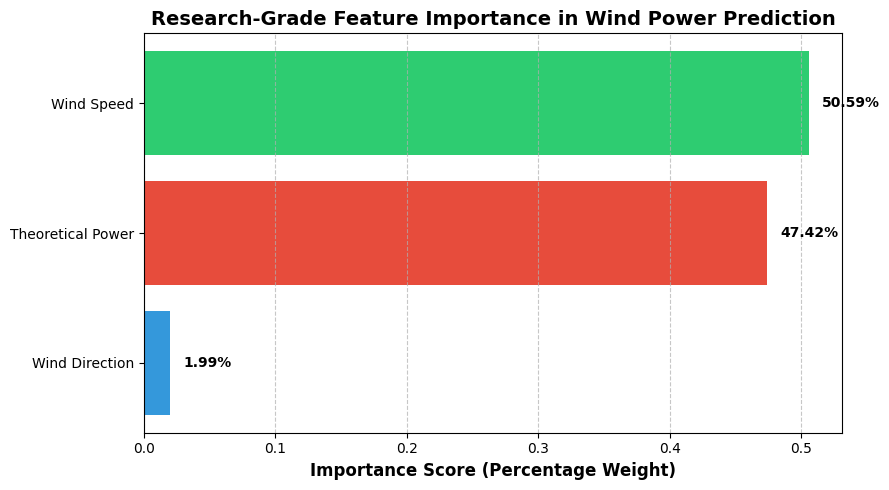

--- MODEL COMPARISON TABLE ---
            Model  R2 Score (%)  RMSE (kW)
Linear Regression         96.59     242.18
    Random Forest         96.74     236.85
          XGBoost         97.20     219.59


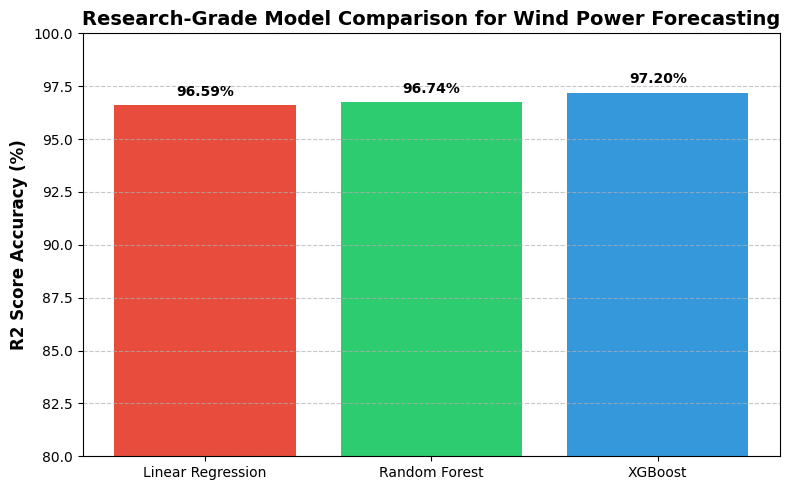


--- LIVE TURBINE POWER PREDICTION ---
Wind Speed: 12.5 m/s
Theoretical Power: 3400.0 KWh
Wind Direction: 180.0°
--> Model Prediction: Turbine will generate approximately **3289.699951171875 kW** of power!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load and Clean Dataset
df = pd.read_csv('T1.csv')

df = df.rename(columns={
    'LV ActivePower (kW)': 'active_power',
    'Wind Speed (m/s)': 'wind_speed',
    'Theoretical_Power_Curve (KWh)': 'theoretical_power',
    'Wind Direction (°)': 'wind_direction'
})

# Filter downtime anomalies
df_clean = df[~((df['wind_speed'] > 3.0) & (df['active_power'] < 10))]

# 2. Select Features & Target
X = df_clean[['wind_speed', 'theoretical_power', 'wind_direction']]
y = df_clean['active_power']

# 3. Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Initialize Models
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

results = []
trained_models = {}

# 5. Train & Evaluate Each Model
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    trained_models[name] = model

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    results.append({
        'Model': name,
        'R2 Score (%)': round(r2 * 100, 2),
        'RMSE (kW)': round(rmse, 2)
    })

results_df = pd.DataFrame(results)

# ==========================================
# STEP 1: RESULTS & PREDICTIONS (Scatter Plot)
# ==========================================
xgb_model = trained_models['XGBoost']
y_pred_xgb = xgb_model.predict(X_test)

plt.figure(figsize=(9, 6))
plt.scatter(y_test, y_pred_xgb, color='green', alpha=0.3, label='Cleaned Predictions')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Ideal Fit')
plt.xlabel('Actual Active Power (kW)', fontsize=12, fontweight='bold')
plt.ylabel('Predicted Active Power (kW)', fontsize=12, fontweight='bold')
plt.title('Research-Grade Wind Power Forecasting: Cleaned SCADA Data', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# ==========================================
# STEP 2: FEATURE IMPORTANCE (Random Forest)
# ==========================================
rf_model = trained_models['Random Forest']
importances = rf_model.feature_importances_
feature_names = ['Wind Speed', 'Theoretical Power', 'Wind Direction']

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(importance_df['Feature'], importance_df['Importance'], color=['#3498db', '#e74c3c', '#2ecc71'])
plt.xlabel('Importance Score (Percentage Weight)', fontsize=12, fontweight='bold')
plt.title('Research-Grade Feature Importance in Wind Power Prediction', fontsize=14, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.7)

for index, value in enumerate(importance_df['Importance']):
    plt.text(value + 0.01, index, f'{value*100:.2f}%', va='center', fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# STEP 3: MODEL COMPARISON TABLE & CHART
# ==========================================
print("--- MODEL COMPARISON TABLE ---")
print(results_df.to_string(index=False))

plt.figure(figsize=(8, 5))
bars = plt.bar(results_df['Model'], results_df['R2 Score (%)'], color=['#e74c3c', '#2ecc71', '#3498db'])
plt.ylabel('R2 Score Accuracy (%)', fontsize=12, fontweight='bold')
plt.title('Research-Grade Model Comparison for Wind Power Forecasting', fontsize=14, fontweight='bold')
plt.ylim(80, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.3,
             f'{height:.2f}%', ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# STEP 4: LIVE PREDICTION (Power Output Estimation)
# ==========================================
print("\n" + "="*45)
print("--- LIVE TURBINE POWER PREDICTION ---")
print("="*45)

sample_wind_data = pd.DataFrame([[12.5, 3400.0, 180.0]], columns=['wind_speed', 'theoretical_power', 'wind_direction'])
predicted_power = xgb_model.predict(sample_wind_data)[0]

print(f"Wind Speed: {sample_wind_data['wind_speed'].values[0]} m/s")
print(f"Theoretical Power: {sample_wind_data['theoretical_power'].values[0]} KWh")
print(f"Wind Direction: {sample_wind_data['wind_direction'].values[0]}°")
print(f"--> Model Prediction: Turbine will generate approximately **{round(predicted_power, 2)} kW** of power!")
print("="*45)